In [1]:
import sys

# Make sure Python can find plot_era40.py in the parent directory
sys.path.append("..")
from plot_era40 import NAMES, read

### Adjust date to desired month (format: YYYYMM)

In [2]:
date = "200202"

if date:
    theta_path = "../data_excerpt/theta/theta2pvu_" + date + ".grib"
    uv_path = "../data_excerpt/uv/uv300_" + date + ".grib"
else:
    theta_path = "../data_excerpt/theta/theta2pvu_199812.grib"
    uv_path = "../data_excerpt/uv/uv300_199812.grib"

### Helper functions for computing central latitudes ($\phi_c$)

From MHW: "This central latitude varies with longitude and follows the maximum of the smoothed transient eddy kinetic energy, which is an indication of the main track followed by synoptic systems."

Note that not all grid points are available in the GRIB file, so get_phi_c attempts to find the nearest one.

In [3]:
import numpy as np
from scipy.ndimage import uniform_filter1d

def compute_central_latitudes(lats, lons, u_timeseries, v_timeseries):
    """
    Computes the optimal central latitude (phi_c) for each longitude based on 
    the maximum of smoothed transient eddy kinetic energy (EKE).
    
    Parameters:
    - lats: 1D numpy array of latitudes
    - lons: 1D numpy array of longitudes
    - u_timeseries: 3D numpy array of shape (time, lat, lon) for u-wind
    - v_timeseries: 3D numpy array of shape (time, lat, lon) for v-wind
    
    Returns:
    - central_lats: dictionary mapping each longitude value to its central latitude
    """
    # 1. Compute transient anomalies by removing the time mean (simple high-pass approximation)
    u_mean = np.nanmean(u_timeseries, axis=0, keepdims=True)
    v_mean = np.nanmean(v_timeseries, axis=0, keepdims=True)
    
    u_prime = u_timeseries - u_mean
    v_prime = v_timeseries - v_mean
    
    # 2. Compute Eddy Kinetic Energy (EKE) at each time step, then average over time
    eke = 0.5 * (u_prime**2 + v_prime**2)
    mean_eke = np.nanmean(eke, axis=0) # Shape: (len(lats), len(lons))
    
    central_lats = {}
    
    # 3. Find the latitude of maximum EKE for every longitude
    for lon_idx, lon in enumerate(lons):
        eke_profile = mean_eke[:, lon_idx]
        
        # Smooth the latitude profile to remove local noise (using a window of 5 grid points)
        smoothed_eke = uniform_filter1d(eke_profile, size=5, mode='reflect')
        
        # Optional: restrict search window to extratropics (e.g., latitudes > 20)
        # to prevent tropical noise from skewing the storm track detection.
        valid_mask = (lats >= 20) & (lats <= 80)
        if np.any(valid_mask):
            search_eke = np.where(valid_mask, smoothed_eke, -np.inf)
            max_idx = np.argmax(search_eke)
        else:
            max_idx = np.argmax(smoothed_eke)
            
        central_lats[lon] = lats[max_idx]
        
    return central_lats

def get_phi_c(target_lon, central_lats, lons):
    """Finds the central latitude for a given target longitude by finding the nearest grid point."""
    # Handle wrap-around or negative longitudes if necessary
    target_lon = target_lon % 360
    
    # Find the closest longitude in the actual lons array
    closest_lon = lons[np.abs(lons - target_lon).argmin()]
    return central_lats.get(closest_lon, "N/A")

### Find and compute central latitudes

In [4]:
# get available times in the current grib
# If calling read without a time returns times as the 3rd element:
_, _, times, _ = read(theta_path, NAMES["theta"])

# Load the grid using the first available time
first_time = times[0]
lats, lons, _, fields = read(theta_path, NAMES["theta"], first_time)

# 1. Gather time series data for u and v across all time steps
u_list, v_list = [], []

for t in times:
    _, _, _, fields = read(uv_path, NAMES["uv"], t)
    u_list.append(fields["u"]) 
    v_list.append(fields["v"])

u_timeseries = np.array(u_list) # Shape: (time, lat, lon)
v_timeseries = np.array(v_list)

# 2. Compute central latitudes dynamically
central_lats = compute_central_latitudes(lats, lons, u_timeseries, v_timeseries)

print("Sample phi_c values every 30 degrees of longitude:")
for lon in range(0, 360, 30):
    val = get_phi_c(lon, central_lats, lons)
    val_str = f"{val:.4f}°N" if isinstance(val, (int, float, np.number)) else val
    print(f"Longitude {lon}°: Central Latitude = {val_str}")

Sample phi_c values every 30 degrees of longitude:
Longitude 0°: Central Latitude = 51.0277°N
Longitude 30°: Central Latitude = 62.2425°N
Longitude 60°: Central Latitude = 59.9995°N
Longitude 90°: Central Latitude = 53.2707°N
Longitude 120°: Central Latitude = 70.0927°N
Longitude 150°: Central Latitude = 53.2707°N
Longitude 180°: Central Latitude = 38.6914°N
Longitude 210°: Central Latitude = 36.4484°N
Longitude 240°: Central Latitude = 48.7847°N
Longitude 270°: Central Latitude = 39.8129°N
Longitude 300°: Central Latitude = 44.2988°N
Longitude 330°: Central Latitude = 43.1773°N


### Compute B index

From MHW: "Here B is calculated (every 58 of longitude) as the difference of the average of u for regions 158 of latitude on either side of a central latitude."

In [5]:
import numpy as np

def compute_B_index(lats, lons, theta_field, central_lats):
    """
    Computes the B index for every 5 degrees of longitude.
    
    Parameters:
    - lats: 1D numpy array of latitudes
    - lons: 1D numpy array of longitudes
    - theta_field: 2D numpy array of shape (len(lats), len(lons)) representing theta on 2PVU
    - central_lats: dictionary or array mapping each longitude to its central latitude phi_c
    
    Returns:
    - b_indices: 1D numpy array of B values corresponding to the target longitudes
    """
    b_indices = []
    
    # Target longitudes every 5 degrees
    target_lons = np.arange(0, 360, 5)
    
    for lon in target_lons:
        # Find the index for this longitude
        lon_idx = np.abs(lons - lon).argmin()
        phi_c = central_lats.get(lon, 45.0)  # Default/example central latitude
        
        # Define the poleward and equatorward 15-degree bands
        # Equatorward band: [phi_c - 15, phi_c]
        # Poleward band: [phi_c, phi_c + 15]
        eq_mask = (lats >= phi_c - 15) & (lats < phi_c)
        pole_mask = (lats > phi_c) & (lats <= phi_c + 15)
        
        # Extract theta column at this longitude
        theta_col = theta_field[:, lon_idx]
        
        # Calculate averages for the bands
        theta_eq = np.nanmean(theta_col[eq_mask])
        theta_pole = np.nanmean(theta_col[pole_mask])
        
        # B index is the difference (Poleward average - Equatorward average)
        b_val = theta_pole - theta_eq
        b_indices.append(b_val)
        
    return target_lons, np.array(b_indices)

In [6]:
b_timeseries = []
target_lons = None

for i, t in enumerate(times):
    _, _, _, fields = read(theta_path, NAMES["theta"], t)
    # Extract the potential temperature field on the 2-PVU surface
    # (adjust field key if your dictionary uses a different name, e.g., 'pvu' or 'theta')
    theta_key = list(fields.keys())[0] 
    theta_field = fields[theta_key]
    
    target_lons, b_vals = compute_B_index(lats, lons, theta_field, central_lats)
    b_timeseries.append(b_vals)

b_timeseries = np.array(b_timeseries)  # Shape: (time_steps, 72 longitudes)

# Compute the monthly mean B index profile (similar to climatology profiles in the paper)
mean_b = np.nanmean(b_timeseries, axis=0)

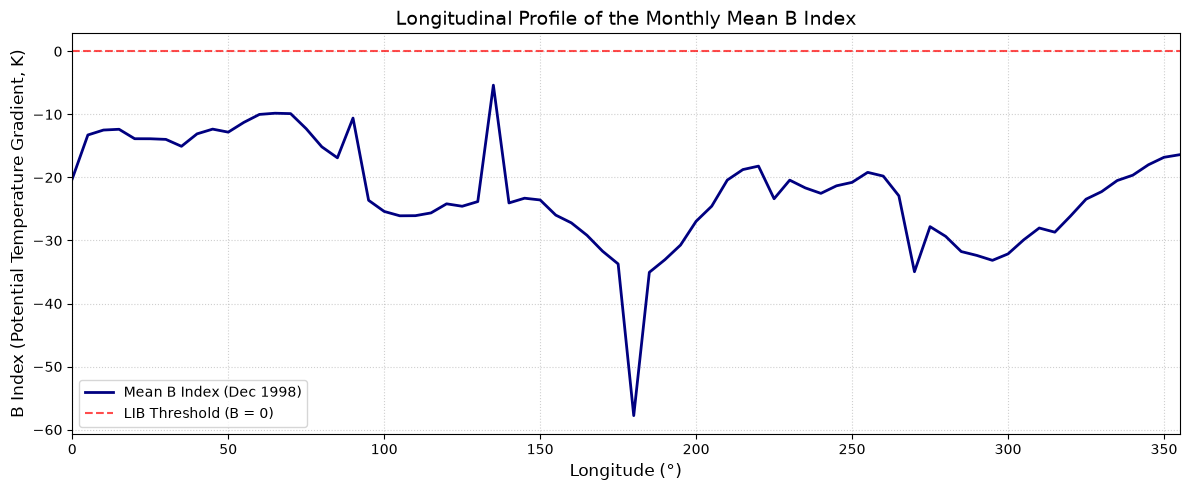

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Plot the monthly mean B index curve
plt.plot(target_lons, mean_b, color='navy', linewidth=2, label='Mean B Index (Dec 1998)')

# Add a reference line at B = 0 (the threshold for blocking / LIB)
plt.axhline(0, color='red', linestyle='--', alpha=0.7, label='LIB Threshold (B = 0)')

# Formatting the plot
plt.title("Longitudinal Profile of the Monthly Mean B Index", fontsize=14)
plt.xlabel("Longitude (°)", fontsize=12)
plt.ylabel("B Index (Potential Temperature Gradient, K)", fontsize=12)
plt.xlim(0, 355)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

### Attempt at a PCA decomposition for one of the B anomalies

Doesn't seem to have been done in MHW, but may be an interesting way to remove some noise out of B anomalies

In [8]:
from sklearn.decomposition import PCA

# First, remove the temporal mean (anomaly matrix)
b_anomaly = b_timeseries - np.mean(b_timeseries, axis=0)

# 2. Apply PCA / POD (extracting the top 18 dominant modes)
n_modes = 17
pca = PCA(n_components=n_modes)
spatial_modes = pca.fit_transform(b_anomaly.T)  # Transpose so features are longitudes
principal_components = pca.components_         # Temporal evolution of each mode
explained_variance = pca.explained_variance_ratio_

print(f"Variance explained by top {n_modes} modes: {np.sum(explained_variance)*100:.2f}%")

Variance explained by top 17 modes: 90.87%
